## The first big project - Professionally You!

### And, Tool use.

### But first: introducing Pushover

Pushover is a nifty tool for sending Push Notifications to your phone.

It's super easy to set up and install!

Simply visit https://pushover.net/ and click 'Login or Signup' on the top right to sign up for a free account, and create your API keys.

Once you've signed up, on the home screen, click "Create an Application/API Token", and give it any name (like Agents) and click Create Application.

Then add 2 lines to your `.env` file:

PUSHOVER_USER=_put the key that's on the top right of your Pushover home screen and probably starts with a u_  
PUSHOVER_TOKEN=_put the key when you click into your new application called Agents (or whatever) and probably starts with an a_

Remember to save your `.env` file, and run `load_dotenv(override=True)` after saving, to set your environment variables.

Finally, click "Add Phone, Tablet or Desktop" to install on your phone.

In [1]:
# imports

from dotenv import load_dotenv
from openai import OpenAI
import json
import os
import requests
from pypdf import PdfReader
import gradio as gr

In [2]:
# The usual start

load_dotenv(override=True)
openai = OpenAI()

## pushover 세팅

In [3]:
# For pushover

pushover_user = os.getenv("PUSHOVER_USER")
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_url = "https://api.pushover.net/1/messages.json"

if pushover_user:
    print(f"Pushover user found and starts with {pushover_user[0]}")
else:
    print("Pushover user not found")

if pushover_token:
    print(f"Pushover token found and starts with {pushover_token[0]}")
else:
    print("Pushover token not found")

Pushover user found and starts with u
Pushover token found and starts with a


In [4]:
def push(message):
    print(f"Push: {message}")
    payload = {"user": pushover_user, "token": pushover_token, "message": message}
    requests.post(pushover_url, data=payload)

In [5]:
push("HEY!!")

Push: HEY!!


# 1.  LLM Function Calling with Push Alerts

# TooL = JSON + if문

Function tool 기능 사용

https://developers.openai.com/api/docs/guides/function-calling


함수를 chatgpt에세 전달하기 위해서 JSON 으로 반듬

In [6]:
def record_user_details(email, name="Name not provided", notes="not provided"):
    # 사용자가 연락 의사를 밝히며 이메일을 남겼을 때 호출되는 함수
    # name, notes는 선택값이라 제공되지 않으면 기본 문자열로 채워짐
    push(f"Recording interest from {name} with email {email} and notes {notes}")
    # 알림 전송 후 LLM에게 돌려줄 결과값 (도구 호출이 정상 처리됐다는 표시)
    return {"recorded": "ok"}

In [7]:
# OpenAI 함수 호출(tool calling)을 위한 스키마 정의
# LLM이 이 도구를 언제, 어떻게 호출해야 하는지 설명하는 부분
record_user_details_json = {
    "name": "record_user_details",  # 실제 호출될 파이썬 함수 이름과 일치해야 함
    "description": "Use this tool to record that a user is interested in being in touch and provided an email address",
    # ↑ LLM이 "이 도구를 언제 써야 하는지" 판단하는 기준이 되는 설명
    "parameters": {
        "type": "object",
        "properties": {
            "email": {
                "type": "string",
                "description": "The email address of this user"
                # email은 필수값 (required에 포함됨)
            },
            "name": {
                "type": "string",
                "description": "The user's name, if they provided it"
                # name은 선택값 - 사용자가 이름을 안 줬으면 LLM이 생략 가능
            }
            ,
            "notes": {
                "type": "string",
                "description": "Any additional information about the conversation that's worth recording to give context"
                # 대화 맥락을 함께 기록해두면 나중에 누가 왜 연락했는지 파악하기 쉬움
            }
        },
        "required": ["email"],  # email만 필수, name과 notes는 없어도 호출 가능
        "additionalProperties": False  # 정의되지 않은 추가 속성은 허용 안 함
    }
}

In [8]:
def record_unknown_question(question):
    # LLM이 답변할 수 없었던 질문을 기록하는 함수
    # 추후에 어떤 질문에 답을 못했는지 확인하고 보완할 수 있도록 알림 전송
    push(f"Recording {question} asked that I couldn't answer")
    return {"recorded": "ok"}

In [9]:
# record_unknown_question 함수에 대한 도구 스키마
record_unknown_question_json = {
    "name": "record_unknown_question",
    "description": "Always use this tool to record any question that couldn't be answered as you didn't know the answer",
    # ↑ "Always"라는 표현으로 LLM에게 이 도구를 적극적으로 쓰도록 유도
    "parameters": {
        "type": "object",
        "properties": {
            "question": {
                "type": "string",
                "description": "The question that couldn't be answered"
                # 답변 못한 질문 원문 자체를 그대로 기록
            },
        },
        "required": ["question"],  # 질문 내용은 필수
        "additionalProperties": False
    }
}

2가의 함수를 하나의 JSON으로 합침

In [10]:
# 위에서 정의한 두 도구를 OpenAI API의 tools 파라미터 형식에 맞게 묶어줌
# "type": "function" 은 OpenAI 함수 호출 방식 도구임을 나타냄
# 이 리스트가 chat() 메서드에서 client.chat.completions.create(..., tools=tools)로 전달됨
tools = [{"type": "function", "function": record_user_details_json},
        {"type": "function", "function": record_unknown_question_json}]

In [ ]:
tools

# 2. How to Process and Execute Function Requests

LLM이 "이 도구를 써야겠다"고 결정했을 때, 실제로 해당 함수를 실행하고 결과를 반환하는 Tool 실행기입니다.

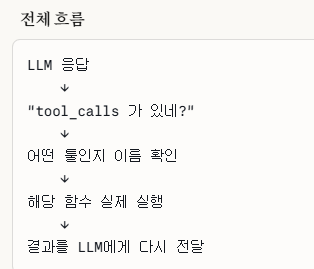

In [11]:
# 도구(tool) 호출 목록을 받아서 하나씩 실행해주는 함수입니다. 이게 바로 그 "IF문"입니다!!

def handle_tool_calls(tool_calls):
    results = []  # 각 도구 호출에 대한 실행 결과를 담을 리스트
    for tool_call in tool_calls:
        tool_name = tool_call.function.name  # LLM이 호출하려는 도구(함수) 이름
        arguments = json.loads(tool_call.function.arguments)  # 문자열(JSON)로 온 인자를 파이썬 dict로 변환
        print(f"Tool called: {tool_name}", flush=True)  # 어떤 도구가 호출됐는지 콘솔에 출력 (디버깅용)

        # 거대한 IF문 등장!!!
        # tool_name에 따라 실제로 실행할 함수를 분기 처리
        # (globals()로 동적 호출하는 방식 대신, 명시적으로 if/elif로 매칭)

        if tool_name == "record_user_details":
            result = record_user_details(**arguments)  # dict를 키워드 인자로 풀어서 함수에 전달 (예: email=..., name=...)
        elif tool_name == "record_unknown_question":
            result = record_unknown_question(**arguments)
        # 주의: 새로운 도구를 tools 리스트에 추가하면, 여기 elif도 함께 추가해줘야 함
        # (안 그러면 result가 정의되지 않아 NameError 발생할 수 있음)

        # OpenAI API가 요구하는 형식대로 결과를 messages에 다시 넣을 수 있게 포장
        # role: "tool" → 이 메시지가 도구 실행 결과임을 나타냄
        # tool_call_id → 어떤 도구 호출에 대한 응답인지 짝을 맞춰주는 식별자
        results.append({"role": "tool","content": json.dumps(result),"tool_call_id": tool_call.id})
    return results

함수 이름을 문자열로 동적 호출하는 Python 테크닉입니다.

이방법을 이용하면 if문을 제거 가능함

In [12]:
# globals()는 현재 모듈(전역 스코프)에 정의된 모든 이름(변수, 함수 등)을 
# {"이름": 객체} 형태의 딕셔너리로 반환합니다.
# 즉, globals()["record_unknown_question"] 은 
# 문자열 "record_unknown_question" 이라는 키로 실제 함수 객체를 찾아오는 것과 같습니다.
# 풀어서 쓰면 globals()["record_unknown_question"] == record_unknown_question 함수 자체예요.

globals()["record_unknown_question"]("this is a really hard question")
# 위에서 찾아온 함수 객체 뒤에 바로 () 를 붙여서 호출
# → record_unknown_question("this is a really hard question") 을 실행하는 것과 완전히 동일한 코드

Push: Recording this is a really hard question asked that I couldn't answer


{'recorded': 'ok'}

## This is a more elegant way that avoids the IF statement.

In [13]:
# IF문을 피할 수 있는 더 깔끔한(elegant) 방식입니다.

def handle_tool_calls(tool_calls):
    results = []  # 도구 실행 결과들을 모아둘 리스트
    for tool_call in tool_calls:
        # LLM이 호출하고자 하는 도구(함수)의 이름 (문자열)
        tool_name = tool_call.function.name

        # LLM이 넘겨준 인자는 JSON 문자열 형태이므로, 파이썬 dict로 변환
        # 예: '{"question": "this is a really hard question"}' → {"question": "this is a really hard question"}
        arguments = json.loads(tool_call.function.arguments)

        print(f"Tool called: {tool_name}", flush=True)  # 디버깅용 로그 출력

        # if/elif로 일일이 분기하지 않고, globals()를 이용해 
        # 문자열 이름(tool_name)과 같은 이름의 함수를 전역 스코프에서 동적으로 찾아옴
        # 예: tool_name이 "record_unknown_question"이면 record_unknown_question 함수 객체를 가져옴
        tool = globals().get(tool_name)
        # .get()을 쓰는 이유: 해당 이름의 함수가 없으면 에러 대신 None을 반환하게 하기 위함

        # tool이 정상적으로 찾아졌다면(None이 아니라면) 
        # **arguments로 dict를 키워드 인자로 풀어서 함수 호출
        # 예: tool(**{"question": "..."}) → tool(question="...")
        # 만약 해당 이름의 함수를 못 찾았다면 빈 dict를 결과로 사용 (에러 방지용 안전장치)
        result = tool(**arguments) if tool else {}

        # OpenAI API 형식에 맞게 도구 실행 결과를 메시지로 포장
        # role: "tool" → 이 메시지가 도구 호출의 결과임을 나타냄
        # tool_call_id → 어떤 tool_call에 대한 응답인지 매칭시켜주는 ID
        results.append({"role": "tool","content": json.dumps(result),"tool_call_id": tool_call.id})
    return results

# 3.  Building AI Assistants: Implementing Tools for Handling Unknown Questions

PDF와 TXT 파일 읽어서 저장

In [14]:
# pypdf의 PdfReader를 이용해 "me/linkedin.pdf" 파일을 읽어옴
# reader.pages 는 PDF의 각 페이지 객체들을 담은 리스트 형태
reader = PdfReader("me/linkedin.pdf")

linkedin = ""  # PDF에서 추출한 텍스트를 누적해서 저장할 빈 문자열 초기화

# PDF의 모든 페이지를 순회하면서 텍스트를 추출
for page in reader.pages:
    text = page.extract_text()  # 해당 페이지의 텍스트를 추출 (이미지만 있는 페이지는 None이나 빈 문자열일 수 있음)
    if text:  # 추출된 텍스트가 있을 때만 (None이나 빈 문자열이 아닐 때) 누적
        linkedin += text

# "me/summary.txt" 파일을 열어서 자기소개 요약 텍스트를 읽어옴
# encoding="utf-8" → 한글 등 다국어 텍스트가 깨지지 않도록 인코딩 지정
with open("me/summary.txt", "r", encoding="utf-8") as f:
    summary = f.read()  # 파일 전체 내용을 문자열로 읽음

name = "Ed Donner"  # 챗봇이 대변할 사람의 이름 (시스템 프롬프트 등에서 사용됨)

시스템 프로프트 작성

In [15]:
# 시스템 프롬프트: LLM에게 "누구를 연기해야 하는지", "어떤 규칙을 따라야 하는지" 알려주는 핵심 지침
# f-string을 사용해 name 변수를 프롬프트 곳곳에 자동으로 삽입
system_prompt = f"당신은 {name}의 역할을 맡아 행동합니다. 당신은 {name}의 웹사이트에서 \
{name}의 경력, 배경, 기술, 경험과 관련된 질문에 답변하고 있습니다. \
당신의 책임은 웹사이트에서의 상호작용에서 {name}을 최대한 충실하게 대변하는 것입니다. \
답변에 활용할 수 있도록 {name}의 배경 요약과 LinkedIn 프로필이 주어집니다. \
웹사이트를 방문한 잠재적 고객이나 미래의 고용주와 대화하듯, 전문적이고 매력적으로 응답하세요. \
어떤 질문이든 답을 모르는 경우, 그것이 경력과 무관하거나 사소한 내용이라도 record_unknown_question 도구를 사용해 \
답변하지 못한 질문을 반드시 기록하세요. \
사용자가 대화를 이어가고 있다면, 이메일로 연락할 수 있도록 자연스럽게 유도하세요. 이메일 주소를 물어보고 \
record_user_details 도구를 사용해 기록하세요. "

# 위에서 만든 기본 지침 뒤에, 실제 참고 자료(요약 + LinkedIn 프로필)를 덧붙임
# += 를 사용해 문자열을 이어붙이는 방식 (프롬프트를 여러 단계로 나눠 작성하면 가독성이 좋아짐)
system_prompt += f"\n\n## 요약(Summary):\n{summary}\n\n## LinkedIn 프로필:\n{linkedin}\n\n"

# 마지막으로 "이 모든 맥락을 바탕으로, 캐릭터를 유지하며 대화하라"는 최종 지시사항 추가
# 이 문장이 프롬프트의 가장 마지막에 위치하는 이유:
# LLM은 보통 프롬프트의 끝부분 지시사항에 더 강하게 집중하는 경향이 있기 때문
system_prompt += f"이 맥락을 바탕으로, 항상 {name}으로서의 역할을 유지하며 사용자와 대화하세요."


https://developers.openai.com/api/docs/guides/function-calling


In [16]:
def chat(message, history):
    # 대화에 사용할 전체 메시지 리스트 구성
    # [시스템 프롬프트] + [기존 대화 기록] + [사용자의 새 메시지] 순서로 합침
    # history는 Gradio ChatInterface(type="messages")가 자동으로 넘겨주는 이전 대화 목록
    messages = [{"role": "system", "content": system_prompt}] + history + [{"role": "user", "content": message}]
    
    done = False  # 최종 응답이 나올 때까지 반복할지 여부를 결정하는 플래그
    while not done:

        # LLM 호출 부분 - tools(도구 목록)도 함께 전달하는 것이 핵심
        # tools를 넘기면 LLM이 필요할 때 직접 함수를 "호출하고 싶다"고 응답할 수 있음

        response = openai.chat.completions.create(model="gpt-5-mini", messages=messages, tools=tools)

        # finish_reason: LLM이 응답을 멈춘 이유
        # - "tool_calls": 도구를 호출하고 싶다는 의미 (아직 최종 답변이 아님)
        # - "stop" 등: 일반적인 답변 완료
        finish_reason = response.choices[0].finish_reason
        
        # LLM이 도구를 호출하고 싶어한다면, 실제로 도구를 실행해줌!
         
        if finish_reason=="tool_calls":
            message = response.choices[0].message  # LLM이 응답한 메시지 객체 (도구 호출 정보 포함)
            tool_calls = message.tool_calls  # 호출하고 싶은 도구들의 목록 (여러 개 가능)
            
            results = handle_tool_calls(tool_calls)  # 실제로 도구들을 실행하고 결과를 받아옴
            
            # 대화 흐름에 "LLM이 도구를 호출했다는 메시지"와 "도구 실행 결과"를 순서대로 추가
            # 이렇게 messages에 쌓아줘야 다음 LLM 호출 시 이전 도구 호출/결과를 참고할 수 있음
            messages.append(message)
            messages.extend(results)
            
            # done은 여전히 False라서 while 루프가 다시 돌면서 LLM을 재호출함
            # → 도구 실행 결과를 바탕으로 LLM이 최종 답변을 만들 기회를 줌
        else:
            # 도구 호출이 없으면 (finish_reason이 "stop" 등) 최종 답변이 나온 것으로 간주
            done = True
            
    # while 루프를 빠져나오면 마지막 응답의 텍스트 내용만 반환
    return response.choices[0].message.content

gradio 로 웹 출력

In [17]:
gr.ChatInterface(chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## And now for deployment

This code is in `app.py`

We will deploy to HuggingFace Spaces.

Before you start: remember to update the files in the "me" directory - your LinkedIn profile and summary.txt - so that it talks about you! Also change `self.name = "Ed Donner"` in `app.py`..  

Also check that there's no README file within the 1_foundations directory. If there is one, please delete it. The deploy process creates a new README file in this directory for you.

1. Visit https://huggingface.co and set up an account  
2. From the Avatar menu on the top right, choose Access Tokens. Choose "Create New Token". Give it WRITE permissions - it needs to have WRITE permissions! Keep a record of your new key.  
3. In the Terminal, run: `uv tool install 'huggingface_hub[cli]'` to install the HuggingFace tool, then `hf auth login --token YOUR_TOKEN_HERE`, like `hf auth login --token hf_xxxxxx`, to login at the command line with your key. Afterwards, run `hf auth whoami` to check you're logged in  
4. Take your new token and add it to your .env file: `HF_TOKEN=hf_xxx` for the future
5. From the 1_foundations folder, enter: `uv run gradio deploy` 
6. Follow its instructions: name it "career_conversation", specify app.py, choose cpu-basic as the hardware, say Yes to needing to supply secrets, provide your openai api key, your pushover user and token, and say "no" to github actions.  

Thank you Robert, James, Martins, Andras and Priya for these tips.  
Please read the next 2 sections - how to change your Secrets, and how to redeploy your Space (you may need to delete the README.md that gets created in this 1_foundations directory).

#### More about these secrets:

If you're confused by what's going on with these secrets: it just wants you to enter the key name and value for each of your secrets -- so you would enter:  
`OPENAI_API_KEY`  
Followed by:  
`sk-proj-...`  

And if you don't want to set secrets this way, or something goes wrong with it, it's no problem - you can change your secrets later:  
1. Log in to HuggingFace website  
2. Go to your profile screen via the Avatar menu on the top right  
3. Select the Space you deployed  
4. Click on the Settings wheel on the top right  
5. You can scroll down to change your secrets (Variables and Secrets section), delete the space, etc.

#### And now you should be deployed!

If you want to completely replace everything and start again with your keys, you may need to delete the README.md that got created in this 1_foundations folder.

Here is mine: https://huggingface.co/spaces/ed-donner/Career_Conversation

I just got a push notification that a student asked me how they can become President of their country 😂😂

For more information on deployment:

https://www.gradio.app/guides/sharing-your-app#hosting-on-hf-spaces

To delete your Space in the future:  
1. Log in to HuggingFace
2. From the Avatar menu, select your profile
3. Click on the Space itself and select the settings wheel on the top right
4. Scroll to the Delete section at the bottom
5. ALSO: delete the README file that Gradio may have created inside this 1_foundations folder (otherwise it won't ask you the questions the next time you do a gradio deploy)
